# QC0426 — Measure

`metadata.hera.policy` — scientific record: append new cells; never edit or
delete executed ones. (Who *executes* a measure cell is set by the session
mode — see the brief.)

Confirm each `# <-- verify` (rig: addresses) and `# <-- validate` (device:
operating limits, wiring) line at bring-up. Cells marked **PATTERN** /
**PROPOSAL** carry `<PLACEHOLDER>` values — review before running.

## Setup

In [1]:
import os
import time

import numpy as np
import scipy.constants as cst

import qcodes
from qcodes import validators
from qcodes.instrument_drivers.stanford_research import SR830
from qcodes.instrument_drivers.tektronix.Keithley_2400 import Keithley_2400

import sweep

from hera.analysis import GateCalibration, field_invB

from drivers.FastBi1K5 import FastBi1K5
from drivers.Lakeshore_335 import Lakeshore_335
from drivers.SRS_DC205 import SRS_DC205
from drivers.async_station import async_station

In [2]:
main_dir = os.getcwd()
sweep.set_basedir(os.path.join(main_dir, "data"))
main_dir

'C:\\Users\\DGG\\VTI_local_data\\zack\\20260621.2-QC0426'

# Connect Instruments

## Magnet

In [3]:
magnet = FastBi1K5('magnet', '192.168.0.10')  # <-- verify address
magnet.status()

Connected to: Fast-Bi-1K5 Magnet Controller
---------- Magnet Status ----------
Field:               : 0.303 Tesla
Current:             : 2.210 A
Voltage:             : 0.008 V
Output Enabled       : True
Persistent Switch On : True
Loop Mode            : CC
Update Mode          : NORMAL
-----------------------------------


## Lakeshore

In [4]:
heater = Lakeshore_335('l335_3', 'GPIB0::10::INSTR')  # <-- verify address
print(heater.sample_temperature())
print(heater.vaporizer_temperature())

Connected to: LSCI 335 (serial:LSA2FM7/#######, firmware:1.4) in 0.42s
1.156
0.0


## Lock-ins

In [5]:
sr0 = SR830('sr0', "GPIB0::17::INSTR")  # <-- verify — current channel (Ithaco preamp output)
sr1 = SR830('sr1', "GPIB0::14::INSTR")  # <-- verify — also the AC drive source
sr2 = SR830('sr2', "GPIB0::19::INSTR")  # <-- verify
sr3 = SR830('sr3', "GPIB0::18::INSTR")  # <-- verify

C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.p

Connected to: Stanford_Research_Systems SR830 (serial:s/n45620, firmware:ver1.07) in 0.10s
Connected to: Stanford_Research_Systems SR830 (serial:s/n83412, firmware:ver1.07) in 0.08s
Connected to: Stanford_Research_Systems SR830 (serial:s/n41639, firmware:ver1.07) in 0.08s


Connected to: Stanford_Research_Systems SR830 (serial:s/n93552, firmware:ver1.07) in 0.09s


C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(


## Keithleys

In [6]:
k_2400 = Keithley_2400('k_2400', 'GPIB0::24::INSTR')  # <-- verify address — back-gate Keithley
k_2400.mode.set('VOLT')
k_2400.volt.set(0)
k_2400.rangei.set(1e-6)
k_2400.rangev.set(21)
k_2400.volt.step = 0.005
k_2400.nplci.set(1)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:0734554, firmware:C17   Jul 16 1999 15:20:40/A02  /G/F) in 0.03s


In [7]:
k_2410 = Keithley_2400('k_2410', 'GPIB0::25::INSTR')  # <-- verify address — Si-gate Keithley
k_2410.mode.set('VOLT')
k_2410.volt.set(0)
k_2410.rangei.set(1e-6)
k_2410.rangev.set(21)
k_2410.volt.step = 0.005
k_2410.volt.inter_delay = 0.01  # Si gate dV/dt pacing - dielectric safety
k_2410.nplci.set(1)

Connected to: KEITHLEY INSTRUMENTS INC. 2410 (serial:1293333, firmware:C30   Mar 17 2006 09:29:29/A02  /J/J) in 0.03s


## DC205 (top gate)

In [8]:
dc205 = SRS_DC205("dc205", "ASRL7::INSTR")  # <-- verify address — top-gate DC205
dc205.ramp_rate = 2  # V/s

Connected to: Stanford_Research_Systems DC205 (serial:s/n20500514, firmware:ver1.80) in 0.03s


In [9]:
# slot: gate-bindings — role aliases (k_tg/k_bg/k_si) from the device card's
# Gate stack section (which instrument drives which gate). The dc205_volt
# wrapper is generic; the k_* role map is device-specific. Each value
# `# <-- validate`.

# Sweepable top-gate parameter — appears in the data as column 'DC_bias'.
def dcbias(vg):
    dc205.ramp_voltage(vg)

dc205_volt = qcodes.Parameter('DC_bias', unit='V', set_cmd=dcbias)

# Gate role aliases (recipes use k_tg / k_bg / k_si):
k_tg = dc205_volt   # top gate <- DC205 (fast axis is dc205_volt, NOT k_tg.volt)   # <-- validate
k_bg = k_2400       # back gate <- Keithley 2400                                     # <-- validate
k_si = k_2410       # Si gate   <- Keithley 2410                                     # <-- validate

# SAFETIES

Run immediately after instrument bring-up, before any sweep.

In [10]:
# slot: gate-validators — operating limits from the device card's gate-
# operating-limits table; commit EXACTLY the card numbers. Each value
# `# <-- validate`. Instrument-level fences go on the RAW instruments
# (dc205 / k_2400 / k_2410); direct calls bypass the role-alias wrapper.
TG_MIN, TG_MAX = -6.0, +7.0    # top gate (dc205_volt), V    # <-- validate
BG_MIN, BG_MAX = -4.5, +4.5    # back gate (k_2400), V        # <-- validate
SI_MIN, SI_MAX = -50.0, +50.0  # Si gate (k_2410), V          # <-- validate
dc205_volt.vals = validators.Numbers(TG_MIN, TG_MAX)
dc205.voltage.vals = validators.Numbers(TG_MIN, TG_MAX)  # instrument-level: direct dc205 calls bypass dc205_volt
k_2400.volt.vals = validators.Numbers(BG_MIN, BG_MAX)
k_2410.volt.vals = validators.Numbers(SI_MIN, SI_MAX)

# Limit lists for sanitize_tg_bg()
tg_lims, bg_lims = [TG_MIN, TG_MAX], [BG_MIN, BG_MAX]

# Session field cap — machine-enforced: magnet.field is a qcodes Parameter,
# so this validator rejects any magnet.field(target) with |B| > B_SESSION_CAP
# before any hardware traffic (and the non-blocking start_field_ramp re-checks
# it too). (Driver max_field_T = 14.0 remains as backstop.)
B_SESSION_CAP = 8.0  # Tesla    # <-- validate (session cap from card/brief)
magnet.field.vals = validators.Numbers(-B_SESSION_CAP, B_SESSION_CAP)

# Temperature setpoint cap — TYPO GUARD ONLY (sample_setpoint(3000) vs 300).
# The real safe T/B envelope is a rig-card item.
T_SESSION_CAP = 310.0  # K    # <-- verify
heater.sample_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)
heater.vaporizer_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)

# Helpers

In [11]:
def spoints(a, b, c):
    return np.linspace(a, b, c)


def sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims):
    """
    Given a list of tg and bg voltages, removes any points which are outside tg_lims and bg_lims
    """
    vtg_new_vec = []
    vbg_new_vec = []
    for ind in range(len(vtg_vec)):
        vtg, vbg = vtg_vec[ind], vbg_vec[ind]
        if vtg < tg_lims[0] or vtg > tg_lims[1] or vbg < bg_lims[0] or vbg > bg_lims[1]:
            pass
        else:
            vtg_new_vec.append(vtg)
            vbg_new_vec.append(vbg)
    return np.array(vtg_new_vec), np.array(vbg_new_vec)

In [12]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 15.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 12e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

# Measurement config

In [13]:
# slot: meas-config — sr0_gain + channel/contact assignments from the device
# card's Measurement setup (current channel + gain, provided contact
# configuration). Each value `# <-- validate`. Always set 'comments' per run —
# structured, current, no inherited text.
meas_config = {
    "sr0": "drain current on B7",  # <-- validate
    "sr0_gain": -1e6,  # ithaco gain    # <-- validate
    "sr1": "T3-T4",  # <-- validate
    "sr2": "B4-B5",  # <-- validate
    "sr3": "T5-B6",  # <-- validate
    "bias_resistor": 100e6,
    "bias_voltage": sr1.amplitude(),
    "lockin_freq": sr1.frequency(),
    "sr0_sens": sr0.sensitivity(),
    "sr1_sens": sr1.sensitivity(),
    "sr2_sens": sr2.sensitivity(),
    "sr3_sens": sr3.sensitivity(),
    "sample_temperature:": heater.sample_temperature(),  # key verbatim (trailing ':') to match this cooldown's metadata
    "Si (V)": k_2410.volt(),
    "comments": "<SET PER RUN>",
}


## QSwitch (contact mux) — LIVE

Contact-mux bring-up and the line/breakout maps are device-specific — from the
device card's Contact map section. `qsw.reset()` is **always forbidden** — it
opens the Si standing closures and drops the Si gate.

In [14]:
from drivers.QSwitch import QSwitch
from drivers.contact_mux import ContactMux

qsw = QSwitch('qswitch', 'ASRL4::INSTR')  # <-- verify address — QSwitch

# Contact label -> QSwitch line. Si standing-closure lines are EXCLUDED.
LINES = {  # <-- validate (from card contact map)
    "T1": 1,  "T2": 3,  "T3": 4,  "T4": 6,  "T5": 7,  "T6": 12, "T7": 13,
    "B1": 8,  "B2": 17, "B3": 23, "B4": 22, "B5": 20, "B6": 19, "B7": 18, "B8": 15,
}
# Instrument port -> front-panel BNC tap.
BREAKOUTS = {  # <-- validate (from card instrument taps)
    "source": 7, "drain": 8,
    "sr1+": 1, "sr1-": 2, "sr2+": 3, "sr2-": 4, "sr3+": 5, "sr3-": 6,
}
SETTLE_S = 4  # <-- validate (calibrated relay settle)

mux = ContactMux(qsw, lines=LINES, breakouts=BREAKOUTS, settle_s=SETTLE_S)
# qsw.reset() ALWAYS FORBIDDEN — drops the Si gate (standing closures).

Connected to: Quantum Machines QSwitch (serial:37, firmware:2.0) in 0.06s


# HERA — session start (2026-06-21 · QC0426)

## HERA bring-up — instrument status (read-only)

In [15]:
# HERA bring-up status read (silent preconditions — read-only)
print("sample T   :", heater.sample_temperature(), "K")
print("vaporizer T:", heater.vaporizer_temperature(), "K")
print("magnet B   :", magnet.field(), "T (measured readback)")
print("PS heater  :", magnet.persistent_switch_on(), "| output:", magnet.output_enabled())
print("B cap       :", magnet.field.vals)


sample T   : 1.156 K
vaporizer T: 0.0 K
magnet B   : 0.3027014520547945 T (measured readback)
PS heater  : True | output: True
B cap       : <Numbers -8.0<=v<=8.0>


## HERA — ramp magnet 0.30 T → 0 T (VERIFY + Step-1 prep)

Bring-up read shows the magnet sitting at **0.303 T**. Session-start VERIFY wants 0 T, and Step 1 (the B = 0 (n, D) gate map / CNP calibration) needs B = 0 — so this ramps to zero.

**Cost:** 0.303 T ÷ 0.137 T/min ≈ **2.2 min**, blocking. `magnet.field()` blocks through the whole ramp; per the rig card, interrupting the *cell* does **not** stop the supply (recovery is another `field()` call), so abort at the instrument if ever needed. No data dir written.

**Precondition:** sample T at base; PS heater on / output enabled (else `field()` raises). If the 0.30 T is intentional, don't run this — tell me why and I'll re-plan.


In [17]:
# Precondition reads (silent preconditions) — read-only
print("sample T :", heater.sample_temperature(), "K   (expect ~base 1.2-1.3 K)")
print("B before :", magnet.field(), "T (measured readback)")
print("PS heater:", magnet.persistent_switch_on(), "| output:", magnet.output_enabled())

# Ramp to 0 T for the B=0 (n,D) gate map / VERIFY. ~0.30 T / 0.137 T/min ~= 2.2 min, blocks.
magnet.field(0.0)

print("B after  :", magnet.field(), "T (measured readback)")


sample T : 1.156 K   (expect ~base 1.2-1.3 K)
B before : 0.3026857808219178 T (measured readback)
PS heater: True | output: True


B after  : -0.0006693972602739725 T (measured readback)


## HERA — E1 kernel-binding probe (read-only)

Autonomy granted (Zack, 2026-06-21). Per VERIFY, the first autonomous execute is a read-only namespace probe confirming this execution path is bound to the operator's instrument-carrying kernel: instruments present, live reads return, kernel pid recorded. No hardware writes. Next: the ramp-to-0 cell, then Gate C liveness.


In [16]:
# E1 kernel-binding probe (read-only). First autonomous execute: confirm this
# execution path is bound to the operator's instrument-carrying kernel before
# any measure cell runs. No hardware writes.
need = ['magnet', 'heater', 'sr0', 'sr1', 'sr2', 'sr3',
        'k_2400', 'k_2410', 'dc205', 'qsw', 'mux', 'meas_config']
g = set(globals())
missing = [n for n in need if n not in g]
print("namespace missing:", missing if missing else "none")
print("kernel pid       :", os.getpid())
print("magnet obj id    :", id(magnet))
print("sample T (live)  :", heater.sample_temperature(), "K")
print("magnet B (live)  :", magnet.field(), "T")
print("Si gate (live)   :", k_2410.volt(), "V")


namespace missing: none
kernel pid       : 36692
magnet obj id    : 2026138800384
sample T (live)  : 1.156 K
magnet B (live)  : 0.3026624246575342 T
Si gate (live)   : 0.0 V


## HERA — Gate C (1/2): route the provided contact configuration

E1 auto (ContactMux routing, inside the device-card config). Select the provided configuration: source=T2, drain=B7 (sr0), sr1=T3–T4, sr2=B4–B5, sr3=T5–B6 (Hall). `settle_s` = 4 s inside `select`. `qsw.reset()` is forbidden (drops the Si standing closures). Then a quick raw lock-in read-back to confirm the contacts are live before the liveness sweep. ~5 s.


In [18]:
# Gate C (part 1) — route provided contact configuration via ContactMux.
print("pre  | T:", heater.sample_temperature(), "K  B:", magnet.field(), "T  "
      "BG:", k_bg.volt(), "V  Si:", k_si.volt(), "V")

mux.select({"source": "T2", "drain": "B7",
            "sr1+": "T3", "sr1-": "T4",
            "sr2+": "B4", "sr2-": "B5",
            "sr3+": "T5", "sr3-": "B6"})
print("contacts selected: source=T2 drain=B7 | sr1=T3-T4 sr2=B4-B5 sr3=T5-B6(Hall)")

# Raw lock-in read-back (gain-uncorrected) to confirm contacts are live.
for nm, sr in [("sr0(I)", sr0), ("sr1", sr1), ("sr2", sr2), ("sr3", sr3)]:
    print(f"  {nm}: X={sr.X():.4e}  P={sr.P():.2f} deg  sens={sr.sensitivity()}")


pre  | T: 1.156 K  B: 0.002709602739726027 T  BG: 0.0 V  Si: 0.0 V


contacts selected: source=T2 drain=B7 | sr1=T3-T4 sr2=B4-B5 sr3=T5-B6(Hall)
  sr0(I): X=-1.9947e-02  P=175.44 deg  sens=0.05
  sr1: X=2.7537e-05  P=-2.90 deg  sens=0.002
  sr2: X=2.4557e-05  P=-3.26 deg  sens=0.002
  sr3: X=5.3644e-06  P=-2.79 deg  sens=0.002


## HERA — Gate C (2/2): 1D BG liveness sweep (`reentry-baseline`)

First-session liveness check on the provided contacts (no reference to compare — judged on its own terms: gate response, smoothness, leakage floor). Sweep **BG ∈ [−4.5, +4.5] V** (full validator range, inclusive edges) at **TG = 0, Si = 0, B = 0**, 91 pts, dwell 1.2 s (4τ at τ = 0.3 s). Read all four lock-ins (X/P) + `k_bg.curr` / `k_si.curr` for live gate leakage. The static read-back already showed alive contacts (Rxx ~1.2–1.4 kΩ); this confirms they *respond* to gating and bounds leakage before the Step-1 map.

**VTI note:** temperature is **not** fp'd per-point (rig card: LS335 has a Grafana co-master, per-point polling has killed a run) — T is captured once in `meas_config`. Leakage watched on `k_bg.curr`; DC205 (TG) has no current monitor. ~2–3 min, writes a run dir. Sweeps at the current lock-in drive — if a CNP peak rails the sens I'll flag a drive/sens change rather than change it silently.


T: 1.155 K  B: 0.0026896301369863014 T
drive: 2.0 V  f: 13.0 Hz
  sr0: tau=0.3s  slope=24  sens=0.05
  sr1: tau=0.3s  slope=24  sens=0.002
  sr2: tau=0.3s  slope=24  sens=0.002
  sr3: tau=0.3s  slope=24  sens=0.002


2026-06-21 23:01:32,616 [INFO] Starting sweep with ID 0


2026-06-21 23:01:32,626 [INFO] Minimum duration 0h 1m 49s


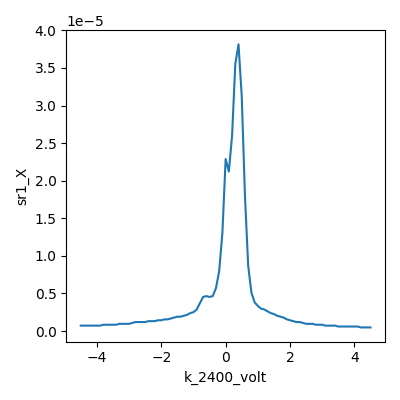

2026-06-21 23:03:43,848 [INFO] Completed in 0h 2m 10s


2026-06-21 23:03:43,849 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260621.2-QC0426\data\0\data.tsv.gz


sweep complete


In [19]:
import numpy as np

# Per-run meas_config refresh (no inherited comment text)
meas_config['comments'] = ("reentry-baseline / Gate C liveness: 1D BG sweep "
                           "[-4.5,4.5] @ TG=0, Si=0, B=0. Contacts T2(src)/B7(drain), "
                           "sr1=T3-T4, sr2=B4-B5, sr3=T5-B6(Hall). Confirm contacts "
                           "alive + Rxx responds to gating; bound gate leakage.")
meas_config['sr0_sens'] = sr0.sensitivity()
meas_config['sr1_sens'] = sr1.sensitivity()
meas_config['sr2_sens'] = sr2.sensitivity()
meas_config['sr3_sens'] = sr3.sensitivity()
meas_config['bias_voltage'] = sr1.amplitude()
meas_config['lockin_freq'] = sr1.frequency()
meas_config['sample_temperature:'] = heater.sample_temperature()
meas_config['Si (V)'] = k_si.volt()

# Preflight (silent preconditions + lock-in front-panel settings)
print("T:", heater.sample_temperature(), "K  B:", magnet.field(), "T")
print("drive:", sr1.amplitude(), "V  f:", sr1.frequency(), "Hz")
for nm, sr in [("sr0", sr0), ("sr1", sr1), ("sr2", sr2), ("sr3", sr3)]:
    print(f"  {nm}: tau={sr.time_constant()}s  slope={sr.filter_slope()}  sens={sr.sensitivity()}")

# Start point
dc205_volt(0.0)     # TG -> 0
k_bg.volt(-4.5)     # BG -> sweep start

# Build fresh station, fp channels, sweep
s = async_station(meas_config)
s.add_comment('reentry-baseline')
s.add_comment('GateC liveness: BG[-4.5,4.5] TG=0 Si=0 B=0')
s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.P).fp(sr2.X).fp(sr2.P).fp(sr3.X).fp(sr3.P)
s.fp(k_bg.curr).fp(k_si.curr)
s.plot(k_bg.volt, sr1.X)
s.sweep(k_bg.volt, spoints(-4.5, 4.5, 91), delay=1.2)
print("sweep complete")


## HERA — Step 1: B=0 (n,D) gate map (`gatemap` → `cnp-and-dline-calibration`)

Axis-aligned megasweep in raw gate voltages (cap ratio not yet trusted). **Fast = TG (`dc205_volt`, col `DC_bias`) over [−6, +7] V, 81 pts; slow = BG over [−4.5, +4.5] V, 41 rows**; Si = 0, B = 0. Recipe-canonical orientation: per-row argmax over TG yields the CNP line V_tg(V_bg) directly → slope = −c_bg/c_tg. Reads all four lock-ins (X/P) + `k_bg.curr`/`k_si.curr` (leakage; DC205 has no current monitor). T not fp'd per-point (LS335 Grafana co-master).

**Why this is robust to the 24 dB/oct under-settling:** a constant fast-axis settling lag shifts the CNP ridge by the same amount in every row → biases the *intercept* (offset), not the *slope* (cap ratio). So this runs at fast_delay = 1.0 s for the ratio; SdH acquisition gets proper settling later (Step 3).

**Cost:** 41×81 = 3321 pts at ~1.25 s/pt + 41 TG row-resets (~6.5 s each) ≈ **~1.25 h**. Spans the full CNP line (expect V_tg ≈ −1.3·V_bg + 0.52: from +6.4 V at BG=−4.5 to −5.3 V at BG=+4.5, all in-range).

**Checkpoint (~row 20, ~37 min):** read the live digest — is the CNP ridge forming and continuous row-to-row, and leakage < 1 nA? Continue if yes; abort and reassess (drive/sens, range) if the ridge is absent/discontinuous or leakage climbs.


T: 1.155 K  B: 0.0026787397260273973 T  Si: 0.0 V
drive: 2.0 V  f: 13.0 Hz


2026-06-21 23:11:52,744 [INFO] Starting megasweep with ID 1


2026-06-21 23:11:52,744 [INFO] Minimum duration 0h 56m 43s


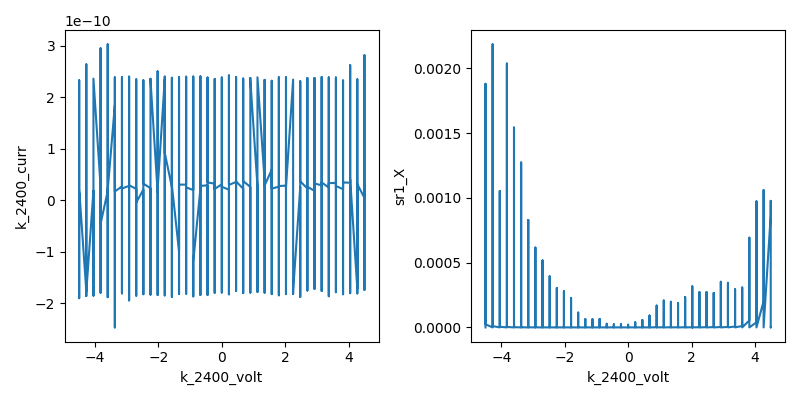

2026-06-22 00:26:00,745 [INFO] Completed in 1h 14m 7s


2026-06-22 00:26:00,746 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260621.2-QC0426\data\1\data.tsv.gz


megasweep complete


In [20]:
import numpy as np
import time

# Per-run meas_config (fresh comment, no inherited text)
meas_config['comments'] = ("gatemap B=0 (n,D) cal: fast=DC_bias(TG)[-6,7]x81, "
                           "slow=BG[-4.5,4.5]x41, Si=0, B=0. CNP-line / cap-ratio "
                           "calibration. Contacts T2(src)/B7(drain) sr1=T3-T4 "
                           "sr2=B4-B5 sr3=T5-B6(Hall).")
meas_config['sr0_sens'] = sr0.sensitivity()
meas_config['sr1_sens'] = sr1.sensitivity()
meas_config['sr2_sens'] = sr2.sensitivity()
meas_config['sr3_sens'] = sr3.sensitivity()
meas_config['bias_voltage'] = sr1.amplitude()
meas_config['lockin_freq'] = sr1.frequency()
meas_config['sample_temperature:'] = heater.sample_temperature()
meas_config['Si (V)'] = k_si.volt()

# Preflight (silent preconditions)
print("T:", heater.sample_temperature(), "K  B:", magnet.field(), "T  Si:", k_si.volt(), "V")
print("drive:", sr1.amplitude(), "V  f:", sr1.frequency(), "Hz")

# Ramp gates to start
k_bg.volt(-4.5)
dc205_volt(-6.0)
time.sleep(3)

# Build station + megasweep (TG fast, BG slow)
s = async_station(meas_config)
s.add_comment('gatemap')
s.add_comment('B=0 nD cal: TGfast[-6,7]x81 BGslow[-4.5,4.5]x41 Si=0')
s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.P).fp(sr2.X).fp(sr2.P).fp(sr3.X).fp(sr3.P)
s.fp(k_bg.curr).fp(k_si.curr)
s.plot(k_bg.volt, k_bg.curr)
s.plot(k_bg.volt, sr1.X)
s.megasweep(k_bg.volt, spoints(-4.5, 4.5, 41),
            dc205_volt, spoints(-6, 7, 81),
            slow_delay=2.0, fast_delay=1.0)
print("megasweep complete")


## HERA — Step 3: SdH spot check, HOLE side (`sdh-spot-check`)

First spot check of the FS-count ladder. Fixed **(n = −3.5×10¹² cm⁻², D = 0)** — the max |n| still within the Onsager model-overlay validity (≤3.5e12), metallic (~55 Ω on both Rxx pairs), hole side (prior-favored for the ABA ML/BL balance). Gate voltages V_tg = −1.560, V_bg = −1.191 (session calibration, run 1; n, D verified exact).

**Field:** 0.20 → 7.95 T sampled **uniform in 1/B** (densest at low B → captures the onset for free), N ≈ 531 at **Δ(1/B) = 1/(3·F_L)**, F_L = 36.2 T. **Dwell 2.5 s** (≈8τ, above the 24 dB/oct settling floor — non-negotiable for the weak ML-tone hunt).

**Lock-in:** sensitivities set to the high-|n| metallic scale — sr1/sr2 → **1e-5** (10 µV FS for Rxx ~1.2 µV, with MR/QH headroom to 8 T), sr3 → **5e-5** (Hall ~29 µV at 8 T). Drive already at metallic 2 V/20 nA. τ / filter_slope untouched (operator-owned). T not fp'd per-point (LS335 Grafana contention).

**Reads:** onset (warm electron-T ~8 K may push it well above the ~100 mT heuristic), tone frequencies vs F_L, and which side gives cleaner SdH. A clean two-tone partition here can be decisive on its own.

**Cost ~1.75 h** (magnet 0.2→7.95 T blocking traverse ~57 min + 531 pts × ~5.5 s/pt incl. 3 s field settle). **Checkpoint ~55 min:** confirm no lock-in overload (clipped sr X), leakage low, and whether oscillations are emerging. Magnet left at ~8 T afterward — the electron-side spot check rides home (no re-traverse).


F_L=36.2 T  d(1/B)=9.21e-03  N=531  Bvec 0.200..7.950 T


T: 1.155 K  B: 0.0026864383561643833 T  Si: 0.0 V  drive: 2.0 V  sens(1/2/3): 1e-05 1e-05 5e-05


at start B = 0.20591720547945203 T
2026-06-22 00:44:27,334 [INFO] Starting sweep with ID 2


2026-06-22 00:44:27,336 [INFO] Minimum duration 0h 22m 7s


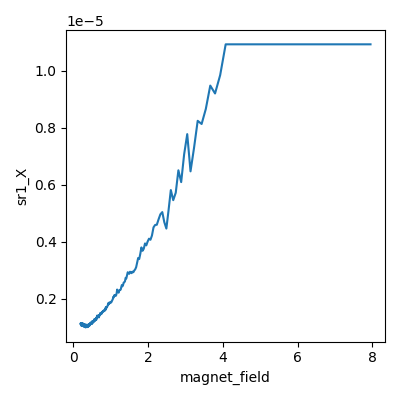

2026-06-22 02:30:48,691 [INFO] Completed in 1h 46m 20s


2026-06-22 02:30:48,692 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260621.2-QC0426\data\2\data.tsv.gz


spot check complete; B now 7.955417890410959 T


In [21]:
import numpy as np
import time
import scipy.constants as cst

# Target: HOLE side, n = -3.5e12 cm^-2, D = 0 (session calibration, run 1)
VTG_T, VBG_T = -1.5597, -1.1914     # gates_for(-3.5e12, 0); n, D verified exact
n_target = 3.5e16                    # m^-2
F_L = cst.h / (4 * cst.e) * n_target # g=4 Luttinger freq (T)
B_LO, B_HI = 0.20, 7.95
dinvB = 1.0 / (3 * F_L)              # Nyquist/3 on F_L
N = int(np.ceil((1 / B_LO - 1 / B_HI) / dinvB)) + 1
Bvec = 1.0 / np.linspace(1 / B_LO, 1 / B_HI, N)   # uniform in 1/B, 0.20 -> 7.95 T
print(f"F_L={F_L:.1f} T  d(1/B)={dinvB:.2e}  N={N}  Bvec {Bvec[0]:.3f}..{Bvec[-1]:.3f} T")

# Lock-in sensitivities for high-|n| metallic SdH (NOT touching tau/filter_slope)
sr1.sensitivity(1e-5); sr2.sensitivity(1e-5); sr3.sensitivity(5e-5)

meas_config['comments'] = (f"sdh-spot-check HOLE n=-3.5e12 D=0 (Vtg={VTG_T},Vbg={VBG_T}); "
                           f"B {B_LO}->{B_HI}T uniform-1/B N={N} (Nyquist/3 F_L={F_L:.1f}T); "
                           f"dwell 2.5s (8tau@24dB); sr1/2=1e-5 sr3=5e-5; Si=0.")
for k, sr in [('sr0_sens', sr0), ('sr1_sens', sr1), ('sr2_sens', sr2), ('sr3_sens', sr3)]:
    meas_config[k] = sr.sensitivity()
meas_config['bias_voltage'] = sr1.amplitude(); meas_config['lockin_freq'] = sr1.frequency()
meas_config['sample_temperature:'] = heater.sample_temperature(); meas_config['Si (V)'] = k_si.volt()

# Preflight
print("T:", heater.sample_temperature(), "K  B:", magnet.field(), "T  Si:", k_si.volt(),
      "V  drive:", sr1.amplitude(), "V  sens(1/2/3):", sr1.sensitivity(), sr2.sensitivity(), sr3.sensitivity())

# Ramp gates to (n, D=0), then magnet to B_lo (blocks until reached)
dc205_volt(VTG_T); k_bg.volt(VBG_T); time.sleep(3)
magnet.field(B_LO)
print("at start B =", magnet.field(), "T")

s = async_station(meas_config)
s.add_comment('sdh-spot-check')
s.add_comment(f'HOLE n=-3.5e12 D=0 B{B_LO}-{B_HI}T invB N{N} dwell2.5')
s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.P).fp(sr2.X).fp(sr2.P).fp(sr3.X).fp(sr3.P)
s.fp(k_bg.curr).fp(k_si.curr)
s.plot(magnet.field, sr1.X)
s.sweep(magnet.field, Bvec, delay=2.5)
print("spot check complete; B now", magnet.field(), "T")


## HERA — Step 3: SdH spot check HOLE, clean re-run (`sdh-spot-check`)

Run 2 clipped: sr1/sr2 railed at 546 Ω (10 µV FS) above ~4 T — the device's high-|n| MR is far stronger than estimated (Rxx ~B^1.8, →~1.6 kΩ at 8 T), and no SdH onset appeared in the clean low-field (0.2–3.8 T), so the oscillations (if any) live above 4 T where run 2 saturated. This re-run fixes the sensitivity and targets the high-field SdH region.

**Same target:** n = −3.5×10¹² cm⁻², D = 0 (V_tg=−1.560, V_bg=−1.191; gates already there). **Rides home 7.95 → 1.0 T** (magnet already at 8 T — no re-traverse), uniform-1/B, N ≈ 96 at Δ(1/B)=1/(3·F_L), F_L=36.2 T, δf≈1.1 T. Dwell 2.5 s.

**Corrected lock-in:** sr1/sr2 → **1e-4** (100 µV FS; handles ~kΩ MR with headroom), sr3 → 5e-5 (Hall ~28 µV at 8 T, was not clipped). Drive 2 V/20 nA.

**Reads:** clean Rxx(B) to 8 T → true onset, and the FFT tone content vs F_L (single ABC tone vs ABA pair). Given the warm electron-T (~8 K) onset is high, the usable 1/B window may be small — this run determines whether the SdH is resolvable here or the device is resolution-limited (→ Step 6 Streda fallback).

**Cost ~1 h** (8→1 T blocking traverse ~51 min + 96 pts). Checkpoint ~30 min: by then the expensive high-field points (8→~3 T) are in — partial FFT on the clean high-field data. Ends at 1 T.


F_L=36.2 T  N=96  Bvec 7.950..1.000 T  df=1.14 T


T: 1.264 K  B: 7.952681246575342 T  Si: 0.0 V  sens(1/2/3): 0.0001 0.0001 5e-05


start B = 7.9526880410958904 T
2026-06-22 02:32:51,237 [INFO] Starting sweep with ID 3


2026-06-22 02:32:51,238 [INFO] Minimum duration 0h 4m 0s


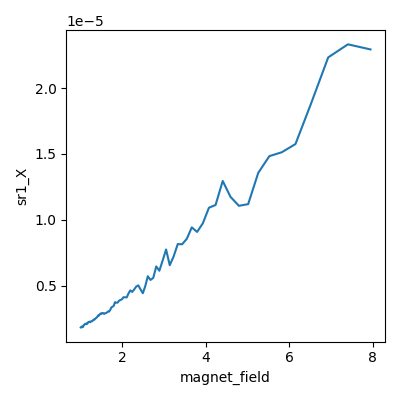

2026-06-22 03:32:27,407 [INFO] Completed in 0h 59m 35s


2026-06-22 03:32:27,408 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260621.2-QC0426\data\3\data.tsv.gz


rerun complete; B now 1.0008080410958904 T


In [22]:
import numpy as np
import time
import scipy.constants as cst

# Same target as run 2 (HOLE, n=-3.5e12, D=0) — gates already there; clean-sens RE-RUN
VTG_T, VBG_T = -1.5597, -1.1914
n_target = 3.5e16
F_L = cst.h / (4 * cst.e) * n_target
B_HI, B_LO = 7.95, 1.0
dinvB = 1.0 / (3 * F_L)
N = int(np.ceil((1 / B_LO - 1 / B_HI) / dinvB)) + 1
Bvec = 1.0 / np.linspace(1 / B_HI, 1 / B_LO, N)   # descending 7.95 -> 1.0 T (ride home)
print(f"F_L={F_L:.1f} T  N={N}  Bvec {Bvec[0]:.3f}..{Bvec[-1]:.3f} T  df={1/(1/B_LO-1/B_HI):.2f} T")

# Corrected sensitivities for strong MR (run 2 clipped at 1e-5)
sr1.sensitivity(1e-4); sr2.sensitivity(1e-4); sr3.sensitivity(5e-5)

meas_config['comments'] = (f"sdh-spot-check HOLE n=-3.5e12 D=0 RERUN clean-sens (Vtg={VTG_T},Vbg={VBG_T}); "
                           f"B {B_HI}->{B_LO}T ride-home uniform-1/B N={N} Nyquist/3 F_L={F_L:.1f}T; "
                           f"dwell2.5s; sr1/2=1e-4 sr3=5e-5 (run2 clipped >4T at 1e-5); Si=0.")
for k, sr in [('sr0_sens', sr0), ('sr1_sens', sr1), ('sr2_sens', sr2), ('sr3_sens', sr3)]:
    meas_config[k] = sr.sensitivity()
meas_config['bias_voltage'] = sr1.amplitude(); meas_config['lockin_freq'] = sr1.frequency()
meas_config['sample_temperature:'] = heater.sample_temperature(); meas_config['Si (V)'] = k_si.volt()

print("T:", heater.sample_temperature(), "K  B:", magnet.field(), "T  Si:", k_si.volt(),
      "V  sens(1/2/3):", sr1.sensitivity(), sr2.sensitivity(), sr3.sensitivity())

# Re-assert gates (already at target), magnet already at ~8 T
dc205_volt(VTG_T); k_bg.volt(VBG_T); time.sleep(2)
magnet.field(B_HI)
print("start B =", magnet.field(), "T")

s = async_station(meas_config)
s.add_comment('sdh-spot-check')
s.add_comment(f'HOLE n=-3.5e12 D=0 RERUN B{B_HI}-{B_LO}T invB N{N} dwell2.5 sens1e-4')
s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.P).fp(sr2.X).fp(sr2.P).fp(sr3.X).fp(sr3.P)
s.fp(k_bg.curr).fp(k_si.curr)
s.plot(magnet.field, sr1.X)
s.sweep(magnet.field, Bvec, delay=2.5)
print("rerun complete; B now", magnet.field(), "T")


## HERA — Step 3: SdH spot check, ELECTRON side (`sdh-spot-check`)

Second spot check (both sides per investigation Step 3). The hole side (run 3) was resolution-limited (warm electron-T → high onset → short 1/B record → broad unstable FFT blob, no robust tone). The electron-side ML tone can be more visible at |n| (investigation Why), so this is a genuinely different test, not a repeat.

**Mirrors hole run 3 exactly** for a clean side-by-side: fixed **(n = +3.5×10¹² cm⁻², D = 0)** (V_tg=+1.734, V_bg=+1.324; metallic, ~50 Ω), **B 1.0 → 7.95 T** ascending (magnet already at 1.0 T — no ramp), uniform-1/B, N = 96 at Δ(1/B)=1/(3·F_L), F_L=36.2 T, δf≈1.1 T. Dwell 2.5 s. **Corrected sensitivity** sr1/sr2 = 1e-4, sr3 = 5e-5 (no clipping at the ~kΩ high-field MR).

**Reads:** onset, tone content vs F_L on the electron side, and whether either side resolves an FS count. If both sides are resolution-limited, that is itself an evidence-based outcome (→ assess Step-6 high-field Streda complement, or report a resolution-limited cannot-tell).

**Cost ~1 h** (1.0→7.95 T traverse ~51 min + 96 pts). Checkpoint ~30 min. Ends at 8 T.


F_L=36.2 T  N=96  Bvec 1.000..7.950 T  df=1.14 T


T: 1.176 K  B: 1.0026946849315068 T  Si: 0.0 V  sens(1/2/3): 0.0001 0.0001 5e-05


start B = 1.0026779589041095 T  Vtg,Vbg set: 1.7337 1.3243
2026-06-22 03:38:01,886 [INFO] Starting sweep with ID 4


2026-06-22 03:38:01,887 [INFO] Minimum duration 0h 4m 0s


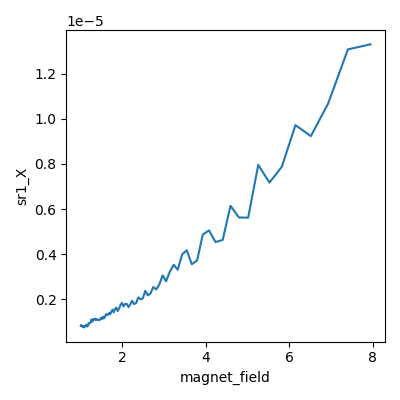

2026-06-22 04:37:38,446 [INFO] Completed in 0h 59m 36s


2026-06-22 04:37:38,448 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260621.2-QC0426\data\4\data.tsv.gz


electron spot check complete; B now 7.955422602739725 T


In [23]:
import numpy as np
import time
import scipy.constants as cst

# ELECTRON side, n = +3.5e12 cm^-2, D = 0 (session calibration, run 1). Mirror of hole run 3.
VTG_T, VBG_T = +1.7337, +1.3243
n_target = 3.5e16
F_L = cst.h / (4 * cst.e) * n_target
B_LO, B_HI = 1.0, 7.95
dinvB = 1.0 / (3 * F_L)
N = int(np.ceil((1 / B_LO - 1 / B_HI) / dinvB)) + 1
Bvec = 1.0 / np.linspace(1 / B_LO, 1 / B_HI, N)   # ascending 1.0 -> 7.95 T (magnet already at 1.0)
print(f"F_L={F_L:.1f} T  N={N}  Bvec {Bvec[0]:.3f}..{Bvec[-1]:.3f} T  df={1/(1/B_LO-1/B_HI):.2f} T")

sr1.sensitivity(1e-4); sr2.sensitivity(1e-4); sr3.sensitivity(5e-5)

meas_config['comments'] = (f"sdh-spot-check ELECTRON n=+3.5e12 D=0 (Vtg={VTG_T},Vbg={VBG_T}); "
                           f"B {B_LO}->{B_HI}T uniform-1/B N={N} Nyquist/3 F_L={F_L:.1f}T; "
                           f"dwell2.5s; sr1/2=1e-4 sr3=5e-5; Si=0. Mirror of hole run3.")
for k, sr in [('sr0_sens', sr0), ('sr1_sens', sr1), ('sr2_sens', sr2), ('sr3_sens', sr3)]:
    meas_config[k] = sr.sensitivity()
meas_config['bias_voltage'] = sr1.amplitude(); meas_config['lockin_freq'] = sr1.frequency()
meas_config['sample_temperature:'] = heater.sample_temperature(); meas_config['Si (V)'] = k_si.volt()

print("T:", heater.sample_temperature(), "K  B:", magnet.field(), "T  Si:", k_si.volt(),
      "V  sens(1/2/3):", sr1.sensitivity(), sr2.sensitivity(), sr3.sensitivity())

# Set ELECTRON gates (from hole side -> sign flip), magnet already at ~1.0 T
dc205_volt(VTG_T); k_bg.volt(VBG_T); time.sleep(2)
magnet.field(B_LO)
print("start B =", magnet.field(), "T  Vtg,Vbg set:", VTG_T, VBG_T)

s = async_station(meas_config)
s.add_comment('sdh-spot-check')
s.add_comment(f'ELECTRON n=+3.5e12 D=0 B{B_LO}-{B_HI}T invB N{N} dwell2.5 sens1e-4')
s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.P).fp(sr2.X).fp(sr2.P).fp(sr3.X).fp(sr3.P)
s.fp(k_bg.curr).fp(k_si.curr)
s.plot(magnet.field, sr1.X)
s.sweep(magnet.field, Bvec, delay=2.5)
print("electron spot check complete; B now", magnet.field(), "T")


## HERA — Step 4: Landau fan, ELECTRON side, D=0 (`landau-fan-vti`)

FS-count fan: n vs B at D=0, per-column SdH FFT → **F(n) vs F_L** to resolve single-pocket (ABC, one tone tracking F_L) vs partition (ABA, f_ML+f_BL=F_L). **Side = electron:** run 4 resolved a robust dominant tone at ~34 T ≈ F_L (clean, both channels, stable across extraction) — de-risking this fan; the hole side (run 3) was resolution-limited (no robust tone).

**Grid:** n ∈ [0.5, 3.5]×10¹² cm⁻² (40 pts, **fast**, D=0 line; ≤3.5e12 keeps the Onsager overlay valid) × B ∈ [7.95, 1.0] T (96 pts, **slow**, uniform-1/B, Δ(1/B)=1/(3·F_Lmax=36 T), inherited from the spot check). B **descending** (rides home from run 4 at 8 T — no re-traverse). Dwell fast 2.5 s / slow 2 s (settled, 24 dB/oct). Sensitivities sr1/sr2=1e-4, sr3=5e-5 (clean, no clip at the ~kΩ high-field MR). 3840 pts.

**Cost ~4.5 h** (field traverse ~51 min + 96 B-rows × ~40 n-pts × ~3.3 s). **Checkpoint ~50 % (~2.2 h, B~2.5 T):** per-column FFT on the high-field rows landed — is F(n) tracking F_L (ABC) or partitioning (ABA)? continue/adjust/abandon. Ends at 1 T.

**Reads (Steps 4–5):** per-n-column SdH FFT → F(n); test Σf = n (Luttinger), overlay on the Onsager forward model (`fs_count_b0`, ≤3.5e12); per channel (sr1, sr2) separately (mosaic check). Single tone on F_L → ABC; pair → ABA.


fan grid 40 n x 96 B = 3840 pts; F_Lmax=36.2T; B 7.95->1.00T


T: 1.27 K  B: 7.952688561643835 T  Si: 0.0 V  sens: 0.0001 0.0001 5e-05


start B = 7.952686986301369 T  Vtg0,Vbg0 = 0.3222 0.2462
2026-06-22 04:43:41,256 [INFO] Starting multimegasweep with ID 5


2026-06-22 04:43:41,257 [INFO] Minimum duration 2h 43m 12s


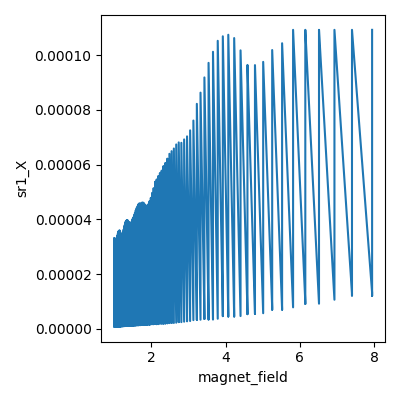

2026-06-22 08:41:15,070 [INFO] Completed in 3h 57m 33s


2026-06-22 08:41:15,071 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260621.2-QC0426\data\5\data.tsv.gz


fan complete; B now 1.002673315068493 T


In [24]:
import numpy as np
import time
import scipy.constants as cst

# ELECTRON-side D=0 Landau fan (clean SdH side, run 4). FS-count fan: per-column SdH FFT.
# n-line gates from session calibration (run 1), gates_for(n, D=0), computed offline.
Vtgs = np.array([0.3222, 0.3584, 0.3946, 0.4308, 0.467, 0.5032, 0.5394, 0.5756, 0.6118,
                 0.6479, 0.6841, 0.7203, 0.7565, 0.7927, 0.8289, 0.8651, 0.9013, 0.9375,
                 0.9737, 1.0099, 1.046, 1.0822, 1.1184, 1.1546, 1.1908, 1.227, 1.2632,
                 1.2994, 1.3356, 1.3718, 1.4079, 1.4441, 1.4803, 1.5165, 1.5527, 1.5889,
                 1.6251, 1.6613, 1.6975, 1.7337])
Vbgs = np.array([0.2462, 0.2738, 0.3014, 0.3291, 0.3567, 0.3844, 0.412, 0.4397, 0.4673,
                 0.495, 0.5226, 0.5502, 0.5779, 0.6055, 0.6332, 0.6608, 0.6885, 0.7161,
                 0.7438, 0.7714, 0.7991, 0.8267, 0.8543, 0.882, 0.9096, 0.9373, 0.9649,
                 0.9926, 1.0202, 1.0479, 1.0755, 1.1032, 1.1308, 1.1584, 1.1861, 1.2137,
                 1.2414, 1.269, 1.2967, 1.3243])  # n = 0.5..3.5e12 cm^-2, D=0
n_vec = np.linspace(0.5e16, 3.5e16, 40)

F_Lmax = cst.h / (4 * cst.e) * 3.5e16          # 36.2 T (highest-n column sets Nyquist)
dinvB = 1.0 / (3 * F_Lmax)
NB = int(np.ceil((1 / 1.0 - 1 / 7.95) / dinvB)) + 1
Bvec = 1.0 / np.linspace(1 / 7.95, 1 / 1.0, NB)  # descending 7.95 -> 1.0 T (ride home from run 4)
print(f"fan grid {len(Vtgs)} n x {NB} B = {len(Vtgs)*NB} pts; F_Lmax={F_Lmax:.1f}T; B {Bvec[0]:.2f}->{Bvec[-1]:.2f}T")

# clean metallic sensitivities (no clip at ~kohm high-field MR)
sr1.sensitivity(1e-4); sr2.sensitivity(1e-4); sr3.sensitivity(5e-5)

meas_config['comments'] = ("landau-fan-vti ELECTRON D=0 FS-count: n[0.5-3.5]e12 (40 fast), "
                           "B[7.95-1.0]T uniform-1/B (96 slow, Nyquist/3 F_L=36T); dwell fast2.5 "
                           "slow2; sr1/2=1e-4 sr3=5e-5; Si=0. Side=electron (cleaner SdH run4; "
                           "hole resolution-limited run3). Per-column SdH FFT -> F(n) vs F_L.")
for k, sr in [('sr0_sens', sr0), ('sr1_sens', sr1), ('sr2_sens', sr2), ('sr3_sens', sr3)]:
    meas_config[k] = sr.sensitivity()
meas_config['bias_voltage'] = sr1.amplitude(); meas_config['lockin_freq'] = sr1.frequency()
meas_config['sample_temperature:'] = heater.sample_temperature(); meas_config['Si (V)'] = k_si.volt()

print("T:", heater.sample_temperature(), "K  B:", magnet.field(), "T  Si:", k_si.volt(),
      "V  sens:", sr1.sensitivity(), sr2.sensitivity(), sr3.sensitivity())

# Start: gates to n-line start, magnet to B start (7.95, already there from run 4)
dc205_volt(Vtgs[0]); k_bg.volt(Vbgs[0]); time.sleep(2)
magnet.field(Bvec[0])
print("start B =", magnet.field(), "T  Vtg0,Vbg0 =", Vtgs[0], Vbgs[0])

s = async_station(meas_config)
s.add_comment('landau-fan-vti')
s.add_comment(f'ELECTRON D=0 n[0.5-3.5]e12x40 B[7.95-1.0]Tx{NB} invB dwell f2.5 s2 sens1e-4')
s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.P).fp(sr2.X).fp(sr2.P).fp(sr3.X).fp(sr3.P)
s.fp(k_bg.curr).fp(k_si.curr)
s.plot(magnet.field, sr1.X)
# B slow, n-line (dc205_volt=k_tg, k_bg.volt) fast
s.multimegasweep([magnet.field], [Bvec], [dc205_volt, k_bg.volt], [Vtgs, Vbgs],
                 slow_delay=2, fast_delay=2.5)
print("fan complete; B now", magnet.field(), "T")


## HERA — Step 6 SCOUT: QH-viability n-sweep at B=7.95 T (operator-directed)

Tests whether clean Landau quantization develops at the field cap before committing the full ~4–5 h Step-6 fan. n-sweep along **D=0, electron, n=0.2→1.5×10¹²** (ν = 1.0→7.8 at 7.95 T — captures ν=2,4,6) at **fixed B=7.95 T**, 60 pts, dwell 2.5 s.

**QH-appropriate sensitivity** (the reason run 5's corner clipped): sr1/sr2 = **5e-4** (Rxx to ~25 kΩ), sr3 = **2e-3** (R_xy to ~100 kΩ; quantized plateaus h/νe²: ν2=12.9 kΩ, ν4=6.5 kΩ, ν6=4.3 kΩ). T not fp'd.

**Read:** do Rxx minima drop toward 0 at integer ν, and does R_xy show plateaus? **If yes** → clean QH; full Step-6 fan is worthwhile (potentially decisive, esp. ABA via the validated `ll_sequence.py`). **If Rxx stays gap-poor** (like run 5's smeared ν≈2.6 corner) → QH marginal at this T/mobility → accept the hedged ABC call and flag lower-T (mK) as the real path.

**Cost ~1 h** (magnet ramp 1.0→7.95 T ≈51 min + 60-pt sweep ≈3 min). Ends at 7.95 T.


T: 1.172 K  B: 1.0027077397260273 T  Si: 0.0 V  sens(1/2/3): 0.0005 0.0005 0.002


ramping magnet to 7.95 T (~51 min from 1 T) ...


at B = 7.95615 T
2026-06-22 13:59:26,613 [INFO] Starting multisweep with ID 6


2026-06-22 13:59:26,614 [INFO] Minimum duration 0h 2m 30s


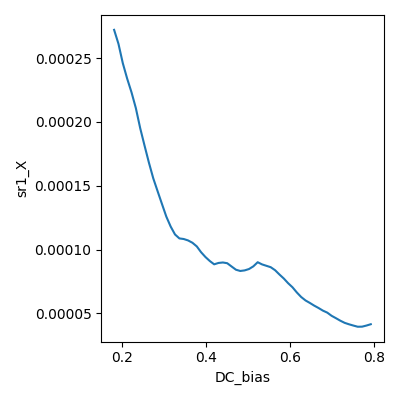

2026-06-22 14:02:09,694 [INFO] Completed in 0h 2m 42s


2026-06-22 14:02:09,695 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260621.2-QC0426\data\6\data.tsv.gz


scout complete; B now 7.9526807123287675 T


In [25]:
import numpy as np
import time

# Step-6 scout: QH-viability n-sweep at fixed B=7.95 T, electron D=0 low-n (n=0.2-1.5e12).
Vtgs = np.array([0.1811, 0.1915, 0.2018, 0.2122, 0.2226, 0.2329, 0.2433, 0.2537, 0.264, 0.2744,
                 0.2848, 0.2951, 0.3055, 0.3159, 0.3262, 0.3366, 0.347, 0.3573, 0.3677, 0.3781,
                 0.3884, 0.3988, 0.4092, 0.4195, 0.4299, 0.4403, 0.4506, 0.461, 0.4714, 0.4817,
                 0.4921, 0.5025, 0.5128, 0.5232, 0.5336, 0.5439, 0.5543, 0.5647, 0.575, 0.5854,
                 0.5957, 0.6061, 0.6165, 0.6268, 0.6372, 0.6476, 0.6579, 0.6683, 0.6787, 0.689,
                 0.6994, 0.7098, 0.7201, 0.7305, 0.7409, 0.7512, 0.7616, 0.772, 0.7823, 0.7927])
Vbgs = np.array([0.1383, 0.1463, 0.1542, 0.1621, 0.17, 0.1779, 0.1858, 0.1938, 0.2017, 0.2096,
                 0.2175, 0.2254, 0.2334, 0.2413, 0.2492, 0.2571, 0.265, 0.273, 0.2809, 0.2888,
                 0.2967, 0.3046, 0.3125, 0.3205, 0.3284, 0.3363, 0.3442, 0.3521, 0.3601, 0.368,
                 0.3759, 0.3838, 0.3917, 0.3997, 0.4076, 0.4155, 0.4234, 0.4313, 0.4392, 0.4472,
                 0.4551, 0.463, 0.4709, 0.4788, 0.4868, 0.4947, 0.5026, 0.5105, 0.5184, 0.5264,
                 0.5343, 0.5422, 0.5501, 0.558, 0.5659, 0.5739, 0.5818, 0.5897, 0.5976, 0.6055])
B_FIXED = 7.95

# QH-appropriate sensitivities (run-5 corner clipped at 1e-4 / 5e-5)
sr1.sensitivity(5e-4); sr2.sensitivity(5e-4); sr3.sensitivity(2e-3)

meas_config['comments'] = ("step6-scout QH-viability: n-sweep D=0 ELECTRON n=0.2-1.5e12 "
                           "(nu 1.0-7.8) at FIXED B=7.95T; sr1/2=5e-4 sr3=2e-3; dwell2.5; Si=0. "
                           "Does clean QH develop (Rxx minima / Rxy plateaus)? gates: gatemap-in-field form.")
for k, sr in [('sr0_sens', sr0), ('sr1_sens', sr1), ('sr2_sens', sr2), ('sr3_sens', sr3)]:
    meas_config[k] = sr.sensitivity()
meas_config['bias_voltage'] = sr1.amplitude(); meas_config['lockin_freq'] = sr1.frequency()
meas_config['sample_temperature:'] = heater.sample_temperature(); meas_config['Si (V)'] = k_si.volt()

print("T:", heater.sample_temperature(), "K  B:", magnet.field(), "T  Si:", k_si.volt(),
      "V  sens(1/2/3):", sr1.sensitivity(), sr2.sensitivity(), sr3.sensitivity())

# Gates to n-start, then ramp magnet 1.0 -> 7.95 T (blocks ~51 min)
dc205_volt(Vtgs[0]); k_bg.volt(Vbgs[0]); time.sleep(2)
print("ramping magnet to", B_FIXED, "T (~51 min from 1 T) ...")
magnet.field(B_FIXED)
print("at B =", magnet.field(), "T")

s = async_station(meas_config)
s.add_comment('field-sweep-1d')   # base recipe for the call surface; scout intent in structured comment
s.add_comment(f'step6-scout n[0.2-1.5]e12 D=0 @B={B_FIXED}T sens5e-4')
s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.P).fp(sr2.X).fp(sr2.P).fp(sr3.X).fp(sr3.P)
s.fp(k_bg.curr).fp(k_si.curr)
s.plot(dc205_volt, sr1.X)
s.multisweep([dc205_volt, k_bg.volt], [Vtgs, Vbgs], delay=2.5)
print("scout complete; B now", magnet.field(), "T")


## HERA — cleanup: ramp magnet to 0 T

Campaign concluded (Step-6 scout shows QH not viable; hedged ABC call accepted pending operator). Device idle — ramp the magnet home from 7.95 T. ~58 min blocking. Gates remain on the low-n D=0 point; no data written.


In [26]:
# Session cleanup: ramp magnet 7.95 T -> 0 T (campaign concluding, device idle).
print("B before:", magnet.field(), "T")
magnet.field(0.0)   # ~58 min blocking ramp
print("B after :", magnet.field(), "T")


B before: 7.952698479452054 T


B after : -0.0008301780821917808 T
